# 04 — Mapas, 16 combinações de renda e densidade, e P90

Este notebook transforma as tabelas da etapa anterior em visualizações que podemos inspecionar. **Todos os cálculos ficam visíveis aqui.** A unidade de análise é o setor censitário; a população serve como peso quando calculamos médias e proporções.

O P90 é a distância que alcança 90% da população acumulada ao ordenar moradores da menor para a maior distância. Chamamos de “muito longe” quem está em setor com distância **igual ou maior** a esse limite. Empates no limite podem fazer a parcela ultrapassar 10%. É uma definição descritiva escolhida para o projeto, não um limite médico.

As faixas de renda e densidade são quartis calculados separadamente dentro de cada capital. As 16 combinações permitem ver se os padrões de distância mudam quando consideramos as duas características ao mesmo tempo. A divisão em 1.500 moradores/km² é apenas a separação simples já prevista: não é o método oficial de aglomeração da OCDE.

**Regra de distância adotada:** o atendimento atribuído é aquele com menor soma das ligações à rua e do percurso pela rede. Os setores com ligação à rua acima de 2 km continuam fora das análises de distância. Favela, CCA e percolação estão fora do escopo atual.

In [1]:
from pathlib import Path
import sys, unicodedata
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"PLANO.md").exists())
BASE = RAIZ/"dados/processados/retomada/base"
DIR = RAIZ/"dados/processados/retomada"
DIST = DIR/"distancias"
SAIDA = DIR/"mapas_grupos_P90"
FIG = RAIZ/"figuras/retomada/mapas"
SAIDA.mkdir(parents=True,exist_ok=True); FIG.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(RAIZ/"scripts"))
import estilo
estilo.aplicar()
capitais = pd.read_csv(BASE/"capitais_resumo.csv")
def slug(nome):
    return unicodedata.normalize("NFKD",nome).encode("ascii","ignore").decode().split(" - ")[0].lower().replace(" ","_")


## 1. Ler os setores e aplicar os filtros definidos

Mantemos setores habitados com ligação do ponto do setor à rua de até 2.000 m e distância finita até um atendimento. Os setores excluídos são registrados, para que o mapa não esconda a cobertura da análise.

In [2]:
partes = []
for versao,sufixo in [("SUS","drive_sus"),("Todos","drive")]:
    for arq in sorted(DIST.glob(f"*_{sufixo}_setores.csv")):
        d = pd.read_csv(arq,dtype={"CD_SETOR":str,"CO_CNES":str})
        d["capital"] = capitais.set_index(capitais.municipio.map(slug)).loc[arq.name.removesuffix(f"_{sufixo}_setores.csv"),"municipio"]
        d["versao"] = versao
        partes.append(d)
bruto = pd.concat(partes,ignore_index=True)
assert bruto.CD_SETOR.is_unique or not bruto.duplicated(["capital","versao","CD_SETOR"]).any()
validos = bruto.loc[(bruto.populacao>0)&(bruto.ligacao_m<=2000)&np.isfinite(bruto.d_m)].copy()
print(f"{len(validos):,} linhas válidas; {validos.capital.nunique()} capitais; versões SUS e Todos.")


181,970 linhas válidas; 26 capitais; versões SUS e Todos.


## 2. Calcular o P90 e marcar os setores muito distantes

A ordenação usa a distância do setor e o peso é sua população. Um setor inteiro recebe a marca de “muito longe” se sua distância for igual ou maior ao P90 da capital. Como os setores não podem ser partidos em frações de moradores neste mapa, a proporção marcada pode passar de 10%.

In [3]:
def quantil_ponderado(x,w,q):
    ordem=np.argsort(np.asarray(x)); x=np.asarray(x)[ordem]; w=np.asarray(w)[ordem]
    return float(x[np.searchsorted(np.cumsum(w),q*w.sum(),side="left")])
limites=[]
for (capital,versao),g in validos.groupby(["capital","versao"]):
    p90=quantil_ponderado(g.d_m,g.populacao,.90)
    idx=g.index
    muito=g.d_m>=p90
    validos.loc[idx,"P90_m"]=p90
    validos.loc[idx,"muito_longe"]=muito
    dist_pop=float(g.loc[muito,"populacao"].sum()/g.populacao.sum())
    limites.append({"capital":capital,"versao":versao,"P90_km":p90/1000,
                    "populacao_valida":int(g.populacao.sum()),
                    "setores_muito_longe":int(muito.sum()),
                    "moradores_muito_longe":int(g.loc[muito,"populacao"].sum()),
                    "parcela_muito_longe_pct":100*dist_pop,
                    "excesso_sobre_10pp":100*dist_pop-10})
limites=pd.DataFrame(limites)
limites.to_csv(SAIDA/"limites_P90_por_capital.csv",index=False)
display(limites.loc[limites.versao=="SUS"].sort_values("P90_km").round(2))


,capital,versao,P90_km,populacao_valida,setores_muito_longe,moradores_muito_longe,parcela_muito_longe_pct,excesso_sobre_10pp
46,São Paulo - SP,SUS,4.73,11451999,2968,1145490,10.00,0.00
24,Maceió - AL,SUS,4.91,957916,171,95876,10.01,0.01
8,Campo Grande - MS,SUS,4.95,896034,200,89812,10.02,0.02
42,Salvador - BA,SUS,5.25,2411113,422,241527,10.02,0.02
0,Belo Horizonte - MG,SUS,5.48,2315560,508,231950,10.02,0.02
20,João Pessoa - PB,SUS,5.56,833932,184,83700,10.04,0.04
16,Fortaleza - CE,SUS,5.73,2428708,451,243426,10.02,0.02
36,Recife - PE,SUS,6.12,1488920,271,148988,10.01,0.01
28,Natal - RN,SUS,6.42,751300,124,75836,10.09,0.09
2,Belém - PA,SUS,6.67,1259378,224,126170,10.02,0.02


## 3. Construir os 16 grupos de renda e densidade

Q1 significa os setores de menor renda ou densidade dentro daquela capital; Q4, os de maior valor. A renda ausente não recebe quartil e fica fora da tabela 4 × 4, mas permanece nas estatísticas totais e no P90. A distância relativa divide cada distância pela média ponderada de sua própria capital: 1 representa a média daquela cidade.

In [4]:
def quartis(v):
    return pd.qcut(v,4,labels=[1,2,3,4],duplicates="drop")
validos["q_renda"]=validos.groupby(["capital","versao"],observed=True).renda_media.transform(quartis)
validos["q_densidade"]=validos.groupby(["capital","versao"],observed=True).densidade.transform(quartis)
validos["d_media_capital_m"]=(validos.populacao*validos.d_m).groupby([validos.capital,validos.versao]).transform("sum")/validos.populacao.groupby([validos.capital,validos.versao]).transform("sum")
validos["d_rel"]=validos.d_m/validos.d_media_capital_m
com_quartis=validos.dropna(subset=["q_renda","q_densidade"]).copy()
com_quartis["q_renda"]=com_quartis.q_renda.astype(int); com_quartis["q_densidade"]=com_quartis.q_densidade.astype(int)
linhas=[]
for (versao,qd,qr),g in com_quartis.groupby(["versao","q_densidade","q_renda"],observed=True):
    linhas.append({"versao":versao,"q_densidade":qd,"q_renda":qr,"setores":len(g),
                   "populacao":int(g.populacao.sum()),
                   "distancia_relativa_media":np.average(g.d_rel,weights=g.populacao),
                   "parcela_muito_longe_pct":100*g.loc[g.muito_longe,"populacao"].sum()/g.populacao.sum()})
grupo16=pd.DataFrame(linhas)
grupo16.to_csv(SAIDA/"grupos_16_renda_densidade.csv",index=False)
display(grupo16.query("versao=='SUS'").pivot(index="q_densidade",columns="q_renda",values="distancia_relativa_media").round(2))


q_renda,1,2,3,4
q_densidade,,,,
1,1.72,1.36,1.09,1.21
2,1.06,0.95,0.88,1.04
3,0.94,0.86,0.83,1.04
4,0.86,0.83,0.89,1.00


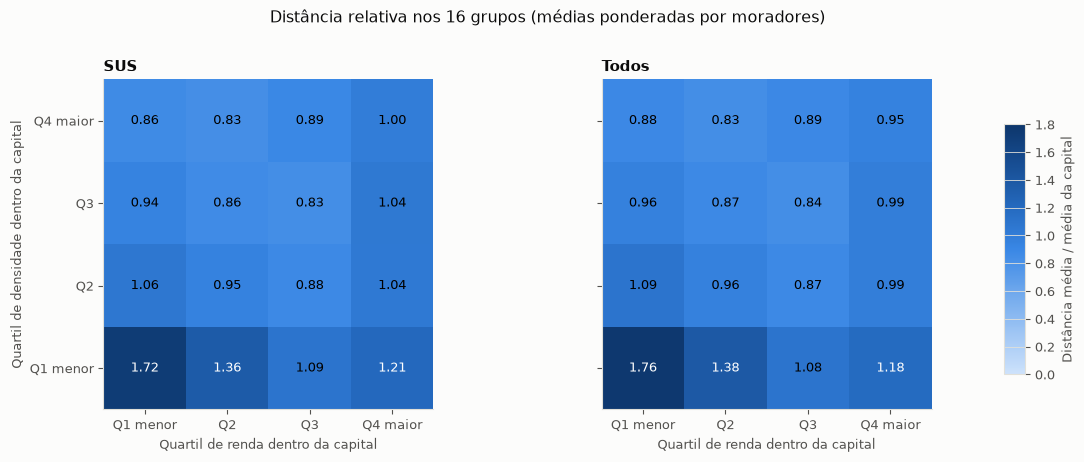

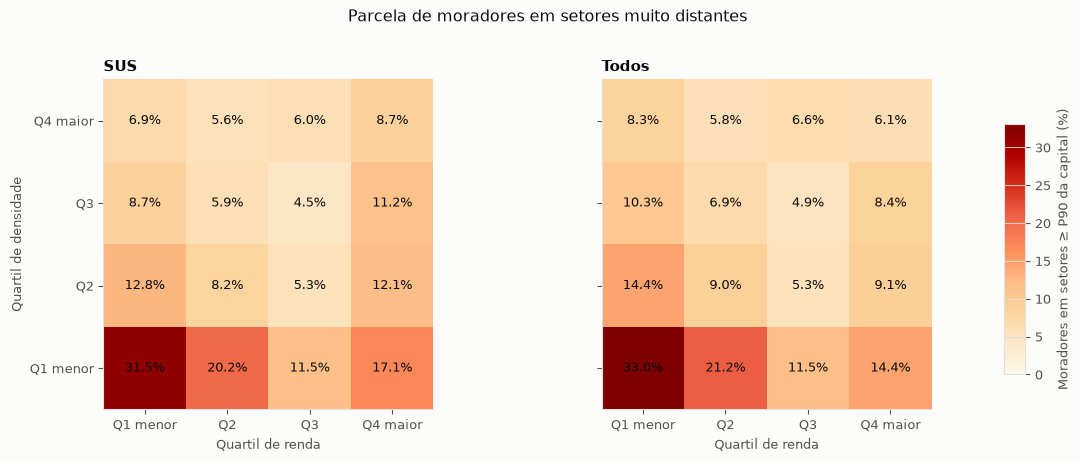

In [5]:
fig,axs=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,versao in zip(axs,["SUS","Todos"]):
    mat=grupo16.query("versao==@versao").pivot(index="q_densidade",columns="q_renda",values="distancia_relativa_media").reindex(index=[4,3,2,1],columns=[1,2,3,4])
    im=ax.imshow(mat,cmap=estilo.CMAP_AZUL,vmin=0,vmax=max(1.8,grupo16.distancia_relativa_media.max()),aspect="equal")
    for i in range(4):
        for j in range(4):
            if pd.notna(mat.iloc[i,j]): ax.text(j,i,f"{mat.iloc[i,j]:.2f}",ha="center",va="center",color="black" if mat.iloc[i,j]<1.1 else "white")
    ax.set(xticks=range(4),xticklabels=["Q1 menor","Q2","Q3","Q4 maior"],yticks=range(4),yticklabels=["Q4 maior","Q3","Q2","Q1 menor"],xlabel="Quartil de renda dentro da capital",title=versao)
axs[0].set_ylabel("Quartil de densidade dentro da capital")
for ax in axs: ax.grid(False)
fig.subplots_adjust(left=.10,right=.85,bottom=.18,top=.84,wspace=.24)
cax=fig.add_axes([.88,.25,.018,.5]); cb=fig.colorbar(im,cax=cax); cb.set_label("Distância média / média da capital")
fig.suptitle("Distância relativa nos 16 grupos (médias ponderadas por moradores)")
fig.savefig(FIG/"01_grupos16_distancia.png",dpi=200); fig.savefig(FIG/"01_grupos16_distancia.pdf"); plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,versao in zip(axs,["SUS","Todos"]):
    mat=grupo16.query("versao==@versao").pivot(index="q_densidade",columns="q_renda",values="parcela_muito_longe_pct").reindex(index=[4,3,2,1],columns=[1,2,3,4])
    im=ax.imshow(mat,cmap="OrRd",vmin=0,vmax=max(20,grupo16.parcela_muito_longe_pct.max()),aspect="equal")
    for i in range(4):
        for j in range(4):
            if pd.notna(mat.iloc[i,j]): ax.text(j,i,f"{mat.iloc[i,j]:.1f}%",ha="center",va="center")
    ax.set(xticks=range(4),xticklabels=["Q1 menor","Q2","Q3","Q4 maior"],yticks=range(4),yticklabels=["Q4 maior","Q3","Q2","Q1 menor"],xlabel="Quartil de renda",title=versao)
axs[0].set_ylabel("Quartil de densidade")
for ax in axs: ax.grid(False)
fig.subplots_adjust(left=.10,right=.85,bottom=.18,top=.84,wspace=.24)
cax=fig.add_axes([.88,.25,.018,.5]); cb=fig.colorbar(im,cax=cax); cb.set_label("Moradores em setores ≥ P90 da capital (%)")
fig.suptitle("Parcela de moradores em setores muito distantes")
fig.savefig(FIG/"02_grupos16_P90.png",dpi=200); fig.savefig(FIG/"02_grupos16_P90.pdf"); plt.show()


## 4. Preparar mapas de Fortaleza

Os mapas usam os polígonos oficiais dos setores e as mesmas classificações da tabela. Primeiro conferimos se cada código aparece uma vez na tabela analítica. O arquivo geográfico pode ter várias partes para um setor; elas recebem a mesma cor e não voltam a contar como observações.

In [6]:
fort=validos.loc[(validos.capital=="Fortaleza - CE")&(validos.versao=="SUS")].copy()
assert fort.CD_SETOR.is_unique
malha=gpd.read_file(RAIZ/"dados/ibge/setores_gpkg/CE_setores_CD2022.gpkg",where="CD_MUN='2304400'",columns=["CD_SETOR","CD_SIT"]).to_crs(32724)
malha=malha.loc[malha.CD_SIT!="9"].copy()
mapa=malha.merge(fort[["CD_SETOR","renda_media","densidade","q_renda","q_densidade","muito_longe","CO_CNES"]],on="CD_SETOR",how="left",validate="many_to_one")
print(f"Setores na malha: {len(malha):,}; com distância SUS válida: {mapa.renda_media.notna().sum():,} (renda pode faltar em alguns).")


Setores na malha: 4,407; com distância SUS válida: 4,280 (renda pode faltar em alguns).


### Mapa de renda

As quatro cores indicam quartis de renda calculados em Fortaleza. Cinza significa que o setor não entrou no recorte válido ou não tem renda informada.

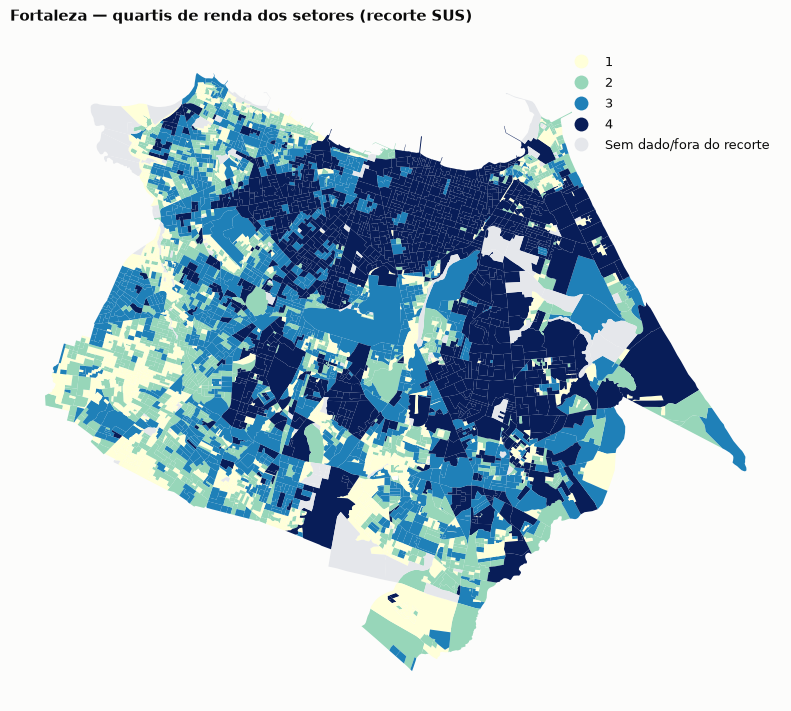

In [7]:
fig,ax=plt.subplots(figsize=(8,8))
mapa.plot(ax=ax,column="q_renda",categorical=True,cmap="YlGnBu",legend=True,missing_kwds={"color":"#e5e7eb","label":"Sem dado/fora do recorte"},linewidth=0)
ax.set_title("Fortaleza — quartis de renda dos setores (recorte SUS)"); ax.set_axis_off(); fig.tight_layout()
fig.savefig(FIG/"03_fortaleza_renda.png",dpi=220); fig.savefig(FIG/"03_fortaleza_renda.pdf"); plt.show()


### Mapa de densidade e separação simples em 1.500 moradores/km²

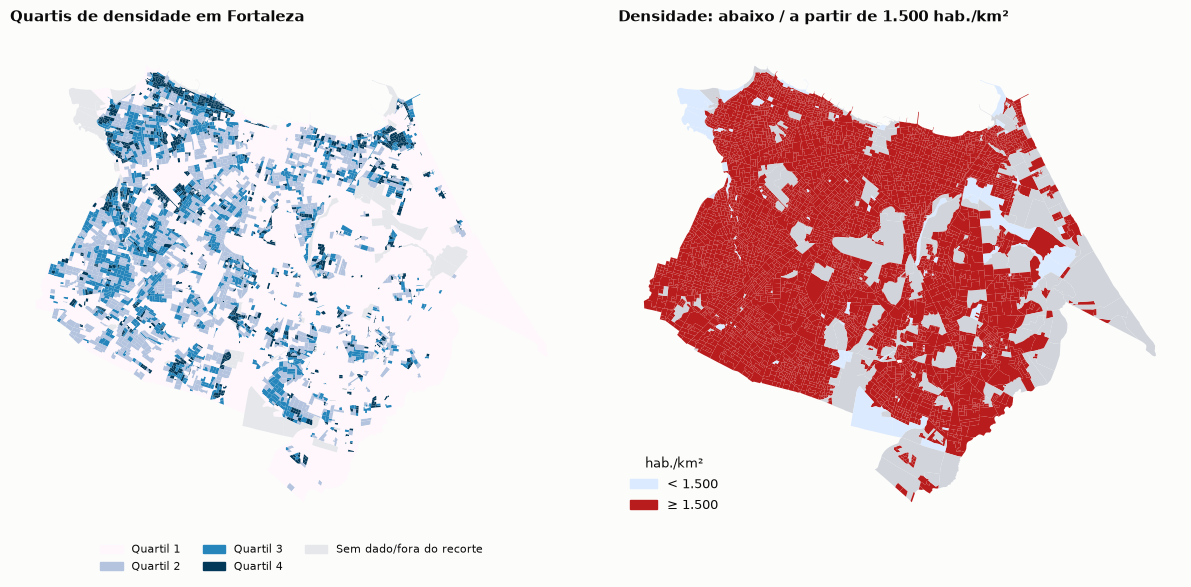

In [8]:
mapa["classe_1500"]=np.select([mapa.densidade.isna(),mapa.densidade>=1500],["Sem dado","≥ 1.500"],default="< 1.500")
fig,axs=plt.subplots(1,2,figsize=(12,7))
mapa.plot(ax=axs[0],column="q_densidade",categorical=True,cmap="PuBu",legend=False,missing_kwds={"color":"#e5e7eb","label":"Sem dado/fora do recorte"},linewidth=0)
axs[0].set_title("Quartis de densidade em Fortaleza")
# A legenda fica abaixo do mapa para não cobrir os setores.
from matplotlib.patches import Patch
cores_q = plt.get_cmap("PuBu", 4)
legenda_q = [Patch(color=cores_q(i), label=f"Quartil {i+1}") for i in range(4)]
legenda_q.append(Patch(color="#e5e7eb", label="Sem dado/fora do recorte"))
axs[0].legend(handles=legenda_q, loc="upper center", bbox_to_anchor=(.5, -.02), ncol=3, frameon=False, fontsize=8)
mapa.plot(ax=axs[1],column="classe_1500",categorical=True,cmap=ListedColormap(["#d1d5db","#dbeafe","#b91c1c"]),legend=True,scheme=None,classification_kwds=None,missing_kwds={"color":"#e5e7eb","label":"Sem dado/fora do recorte"},linewidth=0)
axs[1].set_title("Densidade: abaixo / a partir de 1.500 hab./km²")
# Corrigir legenda para o limiar binário explicitamente.
axs[1].get_legend().remove() if axs[1].get_legend() else None
from matplotlib.patches import Patch
axs[1].legend(handles=[Patch(color="#dbeafe",label="< 1.500"),Patch(color="#b91c1c",label="≥ 1.500")],loc="lower left",title="hab./km²")
for ax in axs: ax.set_axis_off()
fig.tight_layout()
fig.subplots_adjust(bottom=.16, wspace=.08)
fig.savefig(FIG/"04_fortaleza_densidade.png",dpi=220,bbox_inches="tight"); fig.savefig(FIG/"04_fortaleza_densidade.pdf",bbox_inches="tight"); plt.show()


### Mapa das áreas estimadas de atendimento

Cada cor representa uma associação de setores ao mesmo ponto de acesso da rede. Essa é uma partição criada pelo método de distância; não é uma divisão administrativa oficial nem afirma capacidade igual entre unidades.

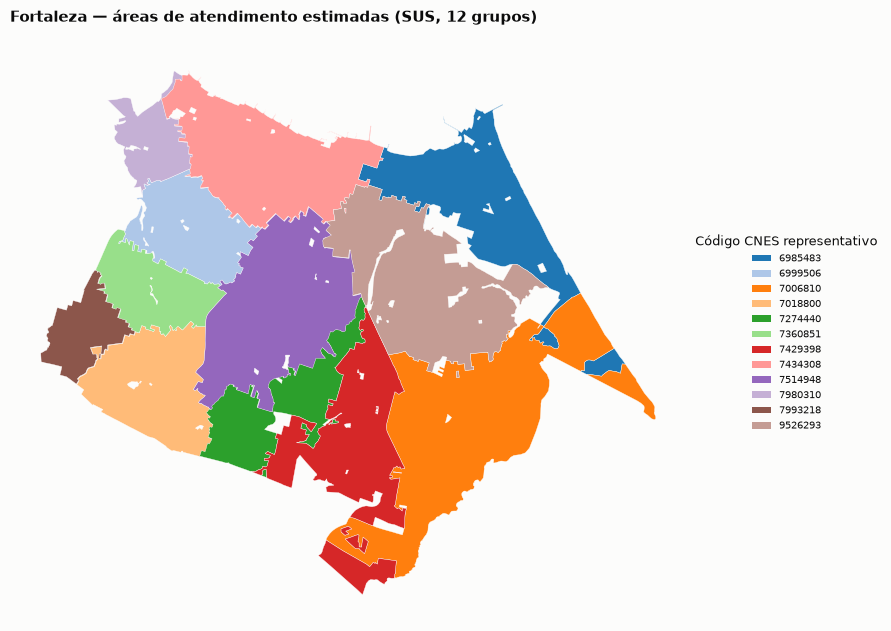

In [9]:
areas=mapa.loc[mapa.CO_CNES.notna()].dissolve(by="CO_CNES",as_index=False)
ids=sorted(areas.CO_CNES.astype(str))
paleta=plt.get_cmap("tab20",max(20,len(ids)))
cores={id_:paleta(i) for i,id_ in enumerate(ids)}
fig,ax=plt.subplots(figsize=(9,9))
for _,r in areas.iterrows(): gpd.GeoSeries([r.geometry],crs=areas.crs).plot(ax=ax,color=cores[str(r.CO_CNES)],linewidth=.25,edgecolor="white")
ax.set_title(f"Fortaleza — áreas de atendimento estimadas (SUS, {len(ids)} grupos)")
ax.set_axis_off()
handles=[Patch(facecolor=cores[i],label=i) for i in ids]
ax.legend(handles=handles,title="Código CNES representativo",loc="center left",bbox_to_anchor=(1,.5),ncol=1,fontsize=7)
fig.tight_layout(); fig.savefig(FIG/"05_fortaleza_areas_atendimento.png",dpi=220,bbox_inches="tight"); fig.savefig(FIG/"05_fortaleza_areas_atendimento.pdf",bbox_inches="tight"); plt.show()


### Mapa dos setores muito distantes

Destaque vermelho = setor com distância igual ou maior ao P90 de Fortaleza. A linha do P90 e a parcela de moradores marcada estão no título para facilitar a explicação.

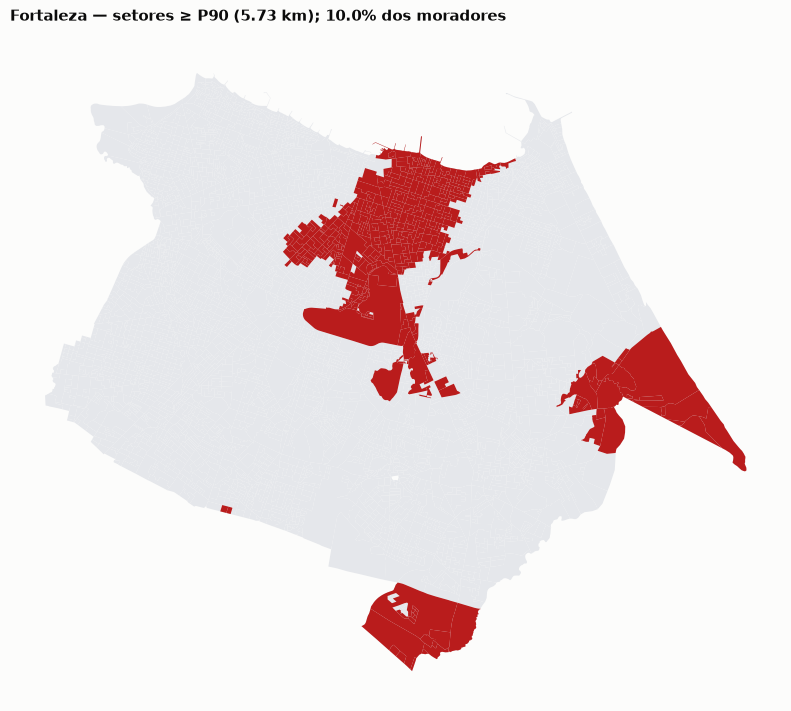

In [10]:
p90=float(fort.P90_m.iloc[0])
mapa["muito_longe"]=mapa.muito_longe.fillna(False)
fig,ax=plt.subplots(figsize=(8,8))
mapa.plot(ax=ax,color="#e5e7eb",linewidth=0)
mapa.loc[mapa.muito_longe].plot(ax=ax,color="#b91c1c",linewidth=0)
parcela=100*fort.loc[fort.muito_longe,"populacao"].sum()/fort.populacao.sum()
ax.set_title(f"Fortaleza — setores ≥ P90 ({p90/1000:.2f} km); {parcela:.1f}% dos moradores")
ax.set_axis_off(); fig.tight_layout(); fig.savefig(FIG/"06_fortaleza_P90.png",dpi=220); fig.savefig(FIG/"06_fortaleza_P90.pdf"); plt.show()


## 5. Salvar uma tabela completa para conferência

Os arquivos CSV preservam números para auditoria e para remontar as figuras. Leia a tabela de P90 por capital como descrição das maiores distâncias dentro do recorte analisado, não como uma classificação de cidades “boas” e “ruins”.

In [11]:
validos.to_csv(SAIDA/"setores_com_P90_e_quartis.csv",index=False)
print("Saídas:")
for p in sorted(SAIDA.glob("*.csv")): print("-",p.name)
print("Figuras:")
for p in sorted(FIG.glob("*")): print("-",p.name)


Saídas:
- grupos_16_renda_densidade.csv
- limites_P90_por_capital.csv
- setores_com_P90_e_quartis.csv
Figuras:
- 01_grupos16_distancia.pdf
- 01_grupos16_distancia.png
- 02_grupos16_P90.pdf
- 02_grupos16_P90.png
- 03_fortaleza_renda.pdf
- 03_fortaleza_renda.png
- 04_fortaleza_densidade.pdf
- 04_fortaleza_densidade.png
- 05_fortaleza_areas_atendimento.pdf
- 05_fortaleza_areas_atendimento.png
- 06_fortaleza_P90.pdf
- 06_fortaleza_P90.png
